<a href="https://colab.research.google.com/github/sohan-paul/Qiskit-fall-fest-portfolio-optimization/blob/main/sp_beginner_challenge2_portfolio_optimizatin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install qiskit qiskit-optimization


In [3]:
import numpy as np


In [4]:
import matplotlib.pyplot as plt


In [5]:
from qiskit_optimization.problems import QuadraticProgram

In [6]:
n=6

In [7]:
np.random.seed(0)
mu=np.random.uniform(0.005,0.015,n)

In [8]:
sigma=np.random.uniform(-0.05,0.5,(n,n))

In [9]:
sigma=np.dot(sigma,sigma.T)

In [10]:
q=0.5

In [11]:
k=6

In [19]:
from qiskit_optimization.converters import QuadraticProgramToQubo

qp = QuadraticProgram()

for i in range(n):
    qp.binary_var(name=f'x_{i}')

qp.minimize(linear=-(1 - q) * mu, quadratic=q * sigma)

# Add the budget constraint
qp.linear_constraint(linear=[1] * n, sense='==', rhs=k)
print("Original Model:\n", qp.export_as_lp_string())

# Convert the constrained problem into an unconstrained QUBO
qubo_converter = QuadraticProgramToQubo()
qubo_model = qubo_converter.convert(qp)

# Convert the unconstrained QUBO to an Ising Hamiltonian
qubit_op, offset = qubo_model.to_ising()

print("Successfully converted to Ising Hamiltonian!")

Original Model:
 \ This file has been generated by DOcplex
\ ENCODING=ISO-8859-1
\Problem name: CPLEX

Minimize
 obj: - 0.005244067520 x_0 - 0.006075946832 x_1 - 0.005513816880 x_2
      - 0.005224415915 x_3 - 0.004618273997 x_4 - 0.005729470565 x_5 + [
      0.693274790277 x_0^2 + 0.659904488879 x_0*x_1 + 1.455564703985 x_0*x_2
      + 0.719043921129 x_0*x_3 + 0.753868085781 x_0*x_4 + 1.124678452864 x_0*x_5
      + 0.447670597183 x_1^2 + 0.873137276461 x_1*x_2 + 0.409408770439 x_1*x_3
      + 0.629156957404 x_1*x_4 + 0.548309481038 x_1*x_5 + 0.902010877250 x_2^2
      + 0.895843777578 x_2*x_3 + 0.998654776095 x_2*x_4 + 1.380504444943 x_2*x_5
      + 0.400613976432 x_3^2 + 0.572452039639 x_3*x_4 + 0.653452713096 x_3*x_5
      + 0.345200499068 x_4^2 + 0.729966174607 x_4*x_5 + 0.549580323665 x_5^2 ]/2
Subject To
 c0: x_0 + x_1 + x_2 + x_3 + x_4 + x_5 = 6

Bounds
 0 <= x_0 <= 1
 0 <= x_1 <= 1
 0 <= x_2 <= 1
 0 <= x_3 <= 1
 0 <= x_4 <= 1
 0 <= x_5 <= 1

Binaries
 x_0 x_1 x_2 x_3 x_4 x_5
En

/tmp/ipykernel_15213/2229866006.py:12: DeprecationWarning: The method ``qiskit_optimization.problems.quadratic_program.QuadraticProgram.export_as_lp_string()`` is deprecated as of Qiskit 0.7.0. It will be removed no earlier than 3 months after the release date. Use prettyprint instead.
  print("Original Model:\n", qp.export_as_lp_string())


In [22]:
!pip install qiskit-algorithms

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 6.7 MB/s eta 0:00:00


In [23]:
from qiskit_algorithms import NumPyMinimumEigensolver
from qiskit_optimization.algorithms import MinimumEigenOptimizer

# Set up the exact classical solver
exact_solver = NumPyMinimumEigensolver()
optimizer = MinimumEigenOptimizer(exact_solver)

# Solve the unconstrained QUBO model
result = optimizer.solve(qubo_model)

# Display the optimal portfolio selection
print(f"Optimal portfolio selection: {result.x}")
print(f"Total number of stocks selected: {sum(result.x)} (Target: {k})")

Optimal portfolio selection: [1. 1. 1. 1. 1. 1.]
Total number of stocks selected: 6.0 (Target: 6)


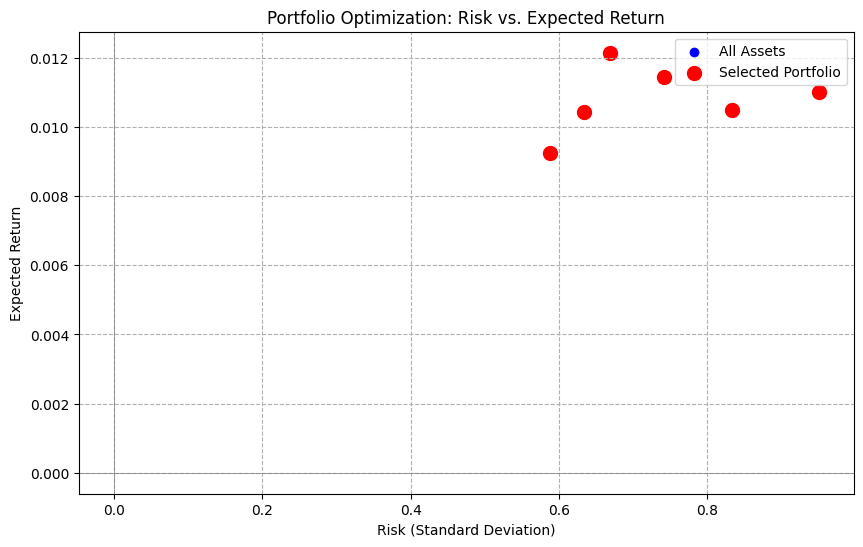

In [24]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate expected returns and risks for all assets
returns = mu
risks = np.sqrt(np.diag(sigma))

# Create scatter plot of risk vs return
plt.figure(figsize=(10, 6))
plt.scatter(risks, returns, color="blue", label="All Assets")

# Highlight selected stocks
selected_indices = np.where(result.x == 1)[0]
plt.scatter(
    risks[selected_indices],
    returns[selected_indices],
    color="red",
    s=100,
    label="Selected Portfolio",
)

# Add labels and title
plt.title("Portfolio Optimization: Risk vs. Expected Return")
plt.xlabel("Risk (Standard Deviation)")
plt.ylabel("Expected Return")
plt.axhline(0, color="grey", linewidth=0.5)
plt.axvline(0, color="grey", linewidth=0.5)
plt.grid(True, linestyle="--")
plt.legend()
plt.show()